# 04 — Segmentation K-Means des patients diabétiques

**Objectif** : identifier des profils de patients et mesurer le taux de réadmission < 30 j par profil.

**Règles respectées** :
1. Colonnes `_log` pour les 5 variables asymétriques (entraînement)
2. `num_lab_procedures` et `number_diagnoses` gardées brutes
3. `StandardScaler` sur toutes les données (pas de train/test en clustering)
4. Interprétation avec les colonnes d'origine (valeurs réelles lisibles)

## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings('ignore')
print('Imports OK')

Imports OK


## 2. Chargement des données

In [2]:
df = pd.read_csv('data_etape2c_encodee.csv')
df_lis = pd.read_csv('data_etape2c_lisible.csv')
print(f'Encodée : {df.shape[0]} lignes x {df.shape[1]} colonnes')
print(f'Lisible : {df_lis.shape[0]} lignes x {df_lis.shape[1]} colonnes')

# Détection automatique de la colonne cible
if 'readmitted_30' in df.columns:
    cible = 'readmitted_30'
elif 'target' in df.columns:
    cible = 'target'
else:
    cible = [c for c in df.columns if 'readmit' in c.lower() or 'target' in c.lower()][0]

print(f'\nCible détectée : "{cible}"')
print(f'Taux de réadmission < 30 j : {df[cible].mean():.1%}')

Encodée : 69987 lignes x 108 colonnes
Lisible : 69987 lignes x 46 colonnes

Cible détectée : "target"
Taux de réadmission < 30 j : 9.0%


## 3. Sélection des variables

**Pour ENTRAÎNER K-Means** : 5 colonnes `_log` + 6 colonnes brutes = 11 variables.

| Variable | Version | Pourquoi |
|---|---|---|
| `time_in_hospital` | `_log` | Très asymétrique |
| `num_medications` | `_log` | Très asymétrique |
| `number_outpatient` | `_log` | Queue longue |
| `number_emergency` | `_log` | Queue longue |
| `number_inpatient` | `_log` | Queue longue |
| `num_lab_procedures` | **brute** | Consigne explicite |
| `number_diagnoses` | **brute** | Consigne explicite, quasi normale |
| `num_procedures` | brute | Borné 0–6 |
| `n_changes` | brute | Borné 0–3 |
| `age` | brute | Ordinal 1–10 |
| `diabetes_complicated` | brute | Binaire 0/1 |

In [3]:
# Variables pour ENTRAÎNER K-Means (règle 1 et 2)
vars_train = [
    'time_in_hospital_log',
    'num_medications_log',
    'number_outpatient_log',
    'number_emergency_log',
    'number_inpatient_log',
    'num_lab_procedures',
    'number_diagnoses',
    'num_procedures',
    'n_changes',
    'age',
    'diabetes_complicated'
]

# Variables pour INTERPRÉTER (règle 4 : colonnes d'origine, valeurs réelles)
vars_interpret = [
    'time_in_hospital',
    'num_medications',
    'number_outpatient',
    'number_emergency',
    'number_inpatient',
    'num_lab_procedures',
    'number_diagnoses',
    'num_procedures',
    'n_changes',
    'age',
    'diabetes_complicated'
]

# Vérifier que toutes les colonnes existent
vars_train = [v for v in vars_train if v in df.columns]
vars_interpret = [v for v in vars_interpret if v in df.columns]

print(f'Variables entraînement : {len(vars_train)}')
print(vars_train)
print(f'\nVariables interprétation : {len(vars_interpret)}')
print(vars_interpret)

Variables entraînement : 11
['time_in_hospital_log', 'num_medications_log', 'number_outpatient_log', 'number_emergency_log', 'number_inpatient_log', 'num_lab_procedures', 'number_diagnoses', 'num_procedures', 'n_changes', 'age', 'diabetes_complicated']

Variables interprétation : 11
['time_in_hospital', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'num_lab_procedures', 'number_diagnoses', 'num_procedures', 'n_changes', 'age', 'diabetes_complicated']


## 4. Scaling (règle 3 : sur toutes les données)

In [4]:
X = df[vars_train].copy()
y = df[cible]

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=vars_train)

print(f'Matrice scaled : {X_scaled.shape}')
print(f'Moyennes ≈ 0 : max = {X_scaled.mean().abs().max():.6f}')
print(f'Écarts-type ≈ 1 : min = {X_scaled.std().min():.4f}, max = {X_scaled.std().max():.4f}')

Matrice scaled : (69987, 11)
Moyennes ≈ 0 : max = 0.000000
Écarts-type ≈ 1 : min = 1.0000, max = 1.0000


## 5. Choix du nombre de clusters (coude + silhouette)

Calcul en cours...
  k=2 : inertie=672913, silhouette=0.132
  k=3 : inertie=611330, silhouette=0.143
  k=4 : inertie=563076, silhouette=0.142
  k=5 : inertie=527719, silhouette=0.133
  k=6 : inertie=487707, silhouette=0.127
  k=7 : inertie=454096, silhouette=0.134
  k=8 : inertie=427870, silhouette=0.143
Terminé !


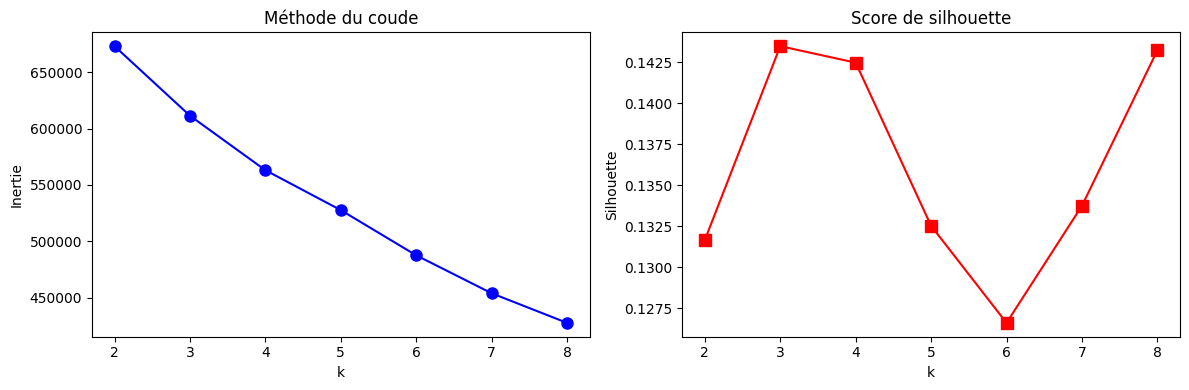


Meilleur k = 3 (silhouette = 0.143)


In [5]:
K_range = range(2, 9)
inertias = []
silhouettes = []

print('Calcul en cours...')
for k in K_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    # sample_size pour éviter le blocage sur 70 000 lignes
    score = silhouette_score(X_scaled, labels, sample_size=10000, random_state=42)
    silhouettes.append(score)
    print(f'  k={k} : inertie={km.inertia_:.0f}, silhouette={score:.3f}')

print('Terminé !')

# Graphiques
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(K_range, inertias, 'bo-', markersize=8)
ax1.set_xlabel('k')
ax1.set_ylabel('Inertie')
ax1.set_title('Méthode du coude')
ax1.set_xticks(list(K_range))

ax2.plot(K_range, silhouettes, 'rs-', markersize=8)
ax2.set_xlabel('k')
ax2.set_ylabel('Silhouette')
ax2.set_title('Score de silhouette')
ax2.set_xticks(list(K_range))

plt.tight_layout()
plt.show()

best_k = list(K_range)[np.argmax(silhouettes)]
print(f'\nMeilleur k = {best_k} (silhouette = {max(silhouettes):.3f})')

## 6. K-Means final

In [13]:
K = 3  # Adapter selon le résultat de la cellule 5

km_final = KMeans(n_clusters=K, n_init=20, random_state=42)
df['cluster'] = km_final.fit_predict(X_scaled)
df_lis['cluster'] = df['cluster']

print(f'K-Means terminé : k = {K}')
print(df['cluster'].value_counts().sort_index())

sil_final = silhouette_score(X_scaled, df['cluster'], sample_size=10000, random_state=42)
print(f'\nSilhouette globale : {sil_final:.3f}')

K-Means terminé : k = 3
cluster
0    32772
1     8202
2    29013
Name: count, dtype: int64

Silhouette globale : 0.143


## 7. Profil des clusters (règle 4 : valeurs réelles lisibles)

In [14]:
# Tableau avec les colonnes d'ORIGINE (pas de _log) pour la lisibilité
profil = df.groupby('cluster')[vars_interpret + [cible]].mean().round(2)
profil['n_patients'] = df.groupby('cluster')[cible].count()
profil['pct'] = (profil['n_patients'] / len(df) * 100).round(1)
profil['taux_readmission'] = profil[cible].apply(lambda x: f'{x:.1%}')

# Réorganiser
ordre = ['n_patients', 'pct', 'taux_readmission'] + vars_interpret
profil = profil[ordre]

print('=== PROFIL DES CLUSTERS (valeurs réelles) ===\n')
display(profil)

=== PROFIL DES CLUSTERS (valeurs réelles) ===



,n_patients,pct,taux_readmission,time_in_hospital,num_medications,number_outpatient,number_emergency,number_inpatient,num_lab_procedures,number_diagnoses,num_procedures,n_changes,age,diabetes_complicated
cluster,,,,,,,,,,,,,,
0,32772,46.8,7.0%,2.58,11.51,0.22,0.07,0.08,33.27,6.42,1.10,0.12,63.78,0.0
1,8202,11.7,11.0%,4.51,14.88,0.29,0.16,0.22,46.39,6.99,1.10,0.43,57.30,1.0
2,29013,41.5,11.0%,6.12,20.58,0.35,0.13,0.27,52.73,8.20,1.89,0.37,69.63,0.0


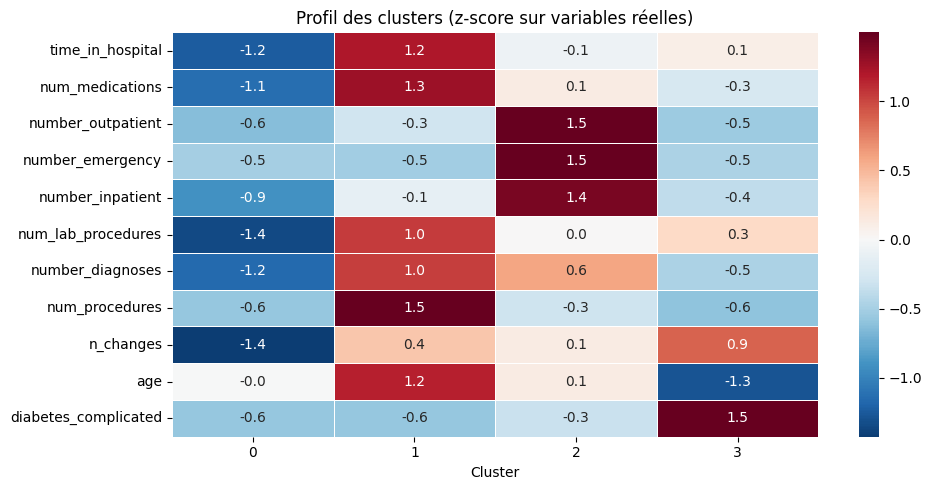

In [8]:
# Heatmap normalisée pour comparer les profils
profil_z = df.groupby('cluster')[vars_interpret].mean()
profil_z = profil_z.apply(lambda c: (c - c.mean()) / c.std())

plt.figure(figsize=(10, 5))
sns.heatmap(profil_z.T, annot=True, fmt='.1f', cmap='RdBu_r', center=0, linewidths=0.5)
plt.title('Profil des clusters (z-score sur variables réelles)')
plt.xlabel('Cluster')
plt.ylabel('')
plt.tight_layout()
plt.show()

## 8. Taux de réadmission par cluster

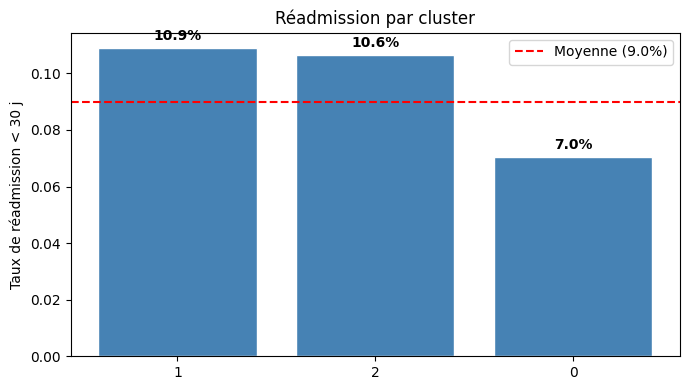

In [15]:
taux = df.groupby('cluster')[cible].mean().sort_values(ascending=False)
moy_globale = df[cible].mean()

plt.figure(figsize=(7, 4))
bars = plt.bar(taux.index.astype(str), taux.values, color='steelblue', edgecolor='white')
plt.axhline(moy_globale, color='red', linestyle='--', label=f'Moyenne ({moy_globale:.1%})')
plt.ylabel('Taux de réadmission < 30 j')
plt.title('Réadmission par cluster')
plt.legend()

for bar, val in zip(bars, taux.values):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.003,
             f'{val:.1%}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

## 9. Visualisation PCA

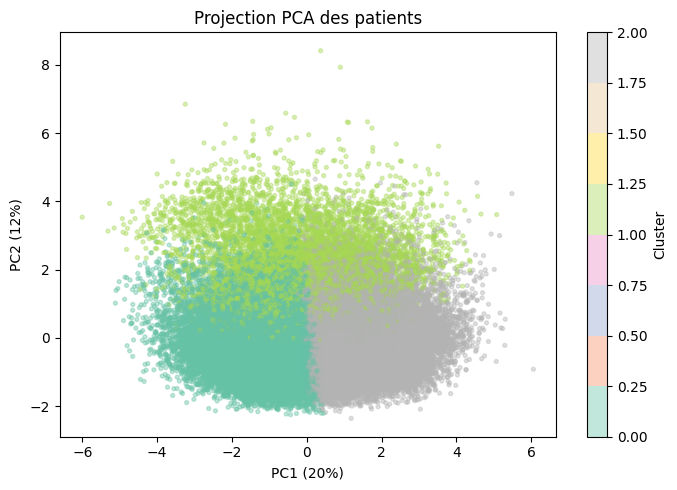

Variance expliquée (2 axes) : 31.8%


In [16]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(7, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df['cluster'], cmap='Set2', alpha=0.4, s=8)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%})')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%})')
plt.title('Projection PCA des patients')
plt.colorbar(label='Cluster')
plt.tight_layout()
plt.show()

print(f'Variance expliquée (2 axes) : {sum(pca.explained_variance_ratio_):.1%}')

## 10. Interprétation avec le fichier lisible

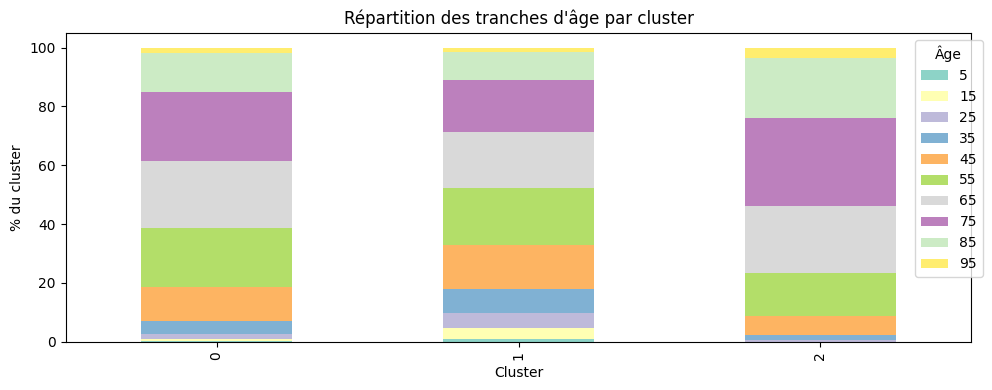


Race par cluster :


race,AfricanAmerican,Asian,Caucasian,Hispanic,Other,Unknown
cluster,,,,,,
0,0.19,0.01,0.73,0.03,0.02,0.03
1,0.26,0.00,0.68,0.02,0.01,0.03
2,0.15,0.01,0.78,0.02,0.01,0.03


In [17]:
# Tranche d'âge par cluster
if 'age' in df_lis.columns:
    ct = pd.crosstab(df_lis['cluster'], df_lis['age'], normalize='index') * 100
    ct.plot(kind='bar', stacked=True, figsize=(10, 4), colormap='Set3')
    plt.title('Répartition des tranches d\'âge par cluster')
    plt.ylabel('% du cluster')
    plt.xlabel('Cluster')
    plt.legend(title='Âge', bbox_to_anchor=(1.02, 1))
    plt.tight_layout()
    plt.show()

# Diagnostic principal
if 'diag_1' in df_lis.columns:
    print('Diagnostic principal par cluster :')
    display(pd.crosstab(df_lis['cluster'], df_lis['diag_1'], normalize='index').round(2))

# Race
if 'race' in df_lis.columns:
    print('\nRace par cluster :')
    display(pd.crosstab(df_lis['cluster'], df_lis['race'], normalize='index').round(2))

## 11. Synthèse

### Profils identifiés (à compléter avec les chiffres de la cellule 7)

- **Cluster à haut risque** : patients âgés, séjours longs, poly-médiqués → taux de réadmission le plus élevé
- **Cluster modéré** : profil standard, proche de la moyenne globale (~9 %)
- **Cluster à bas risque** : patients jeunes, séjours courts, peu de médicaments
- **Cluster historique lourd** : nombreuses hospitalisations antérieures, changements de traitement

### Lien avec la classification (Membre 5)

Le cluster à haut risque doit être prioritaire dans le suivi post-sortie.

### Limites

- Silhouette modeste (~0.2–0.3) : frontières floues, tendances et non catégories étanches
- Signal faible (corrélations ≤ 0.14) : cohérent avec l'exploration
- Données USA 1999–2008, un seul séjour par patient

In [18]:
# Sauvegarde avec la colonne cluster
df.to_csv('data_etape2c_encodee.csv', index=False)
df_lis.to_csv('data_etape2c_lisible.csv', index=False)
print('Sauvegarde OK')

Sauvegarde OK
